# Diabetes Care Information Assistant (Healthcare Cognitive Assistant)
**Roll No: 1024160025 (odd) → Diabetes Care Information Assistant**



In [1]:
# Requirement 4 setup: libraries and NLTK resources
import re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import nltk
warnings.filterwarnings("ignore")
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
from sklearn.metrics.pairwise import cosine_similarity

## 1. Labelled corpus (126 queries, 7 intent categories)

In [2]:
corpus = {
 "symptoms": [
  "what are the symptoms of diabetes",
  "I feel very thirsty and urinate a lot, is that diabetes",
  "early warning signs of type 2 diabetes",
  "why do I feel tired and have blurry vision",
  "what does high blood sugar feel like",
  "do frequent infections indicate diabetes",
  "signs of type 1 diabetes in children",
  "my wounds heal slowly what could be the reason"],
 "diet": [
  "what should I eat if I have diabetes",
  "which foods are bad for blood sugar",
  "can diabetics eat rice and bread",
  "is fruit safe for diabetic patients",
  "best breakfast for a diabetic person",
  "how many carbs should I eat per day",
  "can I have sweets or sugar with diabetes",
  "what is the glycemic index of foods"],
 "medication": [
  "how does metformin work",
  "when should I take insulin",
  "what are the side effects of diabetes medicines",
  "can I stop taking my diabetes tablets",
  "types of insulin injections",
  "how do oral diabetes drugs lower sugar",
  "should I take medicine before or after meals",
  "what is the difference between basal and bolus insulin"],
 "monitoring": [
  "how often should I check my blood sugar",
  "what is a normal fasting glucose level",
  "what does HbA1c mean",
  "how to use a glucometer",
  "what is a good blood sugar level after meals",
  "what is the target HbA1c for diabetics",
  "when is the best time to test sugar",
  "what is continuous glucose monitoring"],
 "complications": [
  "can diabetes damage my kidneys",
  "how does diabetes affect the eyes",
  "what is diabetic neuropathy",
  "does diabetes cause foot ulcers",
  "can diabetes lead to heart disease",
  "what is diabetic retinopathy",
  "long term problems of uncontrolled diabetes",
  "how to prevent nerve damage from diabetes"],
 "lifestyle": [
  "what exercise is good for diabetes",
  "can walking reduce blood sugar",
  "how does weight loss help diabetes",
  "does stress affect blood sugar",
  "how much sleep do diabetics need",
  "can I fast or do yoga with diabetes",
  "does smoking worsen diabetes",
  "how can I prevent type 2 diabetes"],
 "emergency": [
  "my blood sugar is very low and I feel shaky and confused",
  "diabetic person is unconscious",
  "I have fruity breath and vomiting with high sugar",
  "sugar level above 400 what should I do",
  "patient had a seizure and has diabetes",
  "severe hypoglycemia emergency help",
  "I am sweating heavily and feel like fainting with low sugar",
  "signs of diabetic ketoacidosis emergency"],
}

extra = {
 "symptoms": ["what are the warning signs of high sugar", "I am always thirsty and passing urine often", "does sudden weight loss and hunger mean diabetes",
  "how do I know if I have diabetes", "blurred vision and tiredness could it be diabetes", "what are the early signs of diabetes in adults",
  "how is diabetes diagnosed", "tingling in feet and extreme thirst what does it mean", "what is the difference between type 1 and type 2 diabetes symptoms",
  "what tests confirm diabetes"],
 "diet": ["which food items should diabetics avoid", "suggest a healthy diet plan for diabetes", "can I eat potatoes and sugar if diabetic",
  "what snacks are good for diabetic patients", "is rice allowed in a diabetic diet", "are sweets harmful for blood sugar",
  "which fruits are good for sugar patients", "what should I eat for dinner with diabetes", "how many calories should a diabetic eat",
  "is honey or jaggery safe for diabetics"],
 "medication": ["what tablets are used to control diabetes", "how should I take my insulin injection", "does metformin have side effects",
  "when do I need insulin instead of tablets", "what does glimepiride do", "can I take my diabetes medicine with food",
  "what happens if I miss a dose of my diabetes drug", "how long does rapid acting insulin take to work", "what are sulfonylureas and SGLT2 inhibitors",
  "where do I inject insulin"],
 "monitoring": ["what should my sugar reading be before breakfast", "how do I read my glucometer result", "how frequently should I test my glucose",
  "what is the normal range of HbA1c", "how often should I do an HbA1c test", "what is the ideal postprandial glucose",
  "how does a CGM sensor work", "what is a random blood sugar test", "what is the normal blood glucose range",
  "do I need to check sugar daily at home"],
 "complications": ["what organs are affected by diabetes", "can high sugar cause blindness", "how does diabetes harm the kidneys",
  "why do diabetics get foot problems", "does diabetes increase risk of stroke and heart attack", "what is diabetic nephropathy",
  "what are the complications of diabetes", "why does diabetes cause numbness in feet", "how to protect my eyes and kidneys if I am diabetic",
  "can diabetes cause erectile or skin problems"],
 "lifestyle": ["which workouts are best for sugar control", "does a daily walk help diabetics", "how does losing weight improve blood sugar",
  "can stress raise my sugar", "does lack of sleep affect diabetes", "is yoga good for diabetes",
  "should diabetics quit smoking and alcohol", "how to avoid getting type 2 diabetes", "how much physical activity do I need with diabetes",
  "can lifestyle changes reverse prediabetes"],
 "emergency": ["my sugar is 40 and I am sweating and shaky", "diabetic patient passed out what to do", "vomiting and fruity smelling breath with diabetes",
  "blood sugar reading is above 450", "my diabetic mother is having a seizure", "emergency low sugar unresponsive person",
  "feeling faint dizzy and confused with low sugar", "what to do in diabetic ketoacidosis", "urgent help diabetic person not waking up",
  "hypoglycemia coma ambulance"],
}
for k, v in extra.items(): corpus[k] += v
df = pd.DataFrame([(q, i) for i, qs in corpus.items() for q in qs], columns=["query", "intent"])
print(df.shape); print(df.intent.value_counts())
df.sample(5, random_state=1)

(126, 2)
intent
symptoms         18
diet             18
medication       18
monitoring       18
complications    18
lifestyle        18
emergency        18
Name: count, dtype: int64


,query,intent
120,my diabetic mother is having a seizure,emergency
46,does metformin have side effects,medication
73,how does diabetes affect the eyes,complications
90,what exercise is good for diabetes,lifestyle
102,does lack of sleep affect diabetes,lifestyle


## 2. Hierarchical taxonomy (5 major categories × 2 subcategories)

In [3]:
taxonomy = {
 "Understanding Diabetes": ["Types of Diabetes", "Symptoms & Diagnosis"],
 "Monitoring":             ["Glucose Testing", "HbA1c & CGM"],
 "Treatment":              ["Oral Medications", "Insulin Therapy"],
 "Lifestyle Management":   ["Nutrition", "Exercise & Habits"],
 "Complications & Emergencies": ["Chronic Complications", "Acute Emergencies"],
}
intent_to_taxonomy = {
 "symptoms": ("Understanding Diabetes", "Symptoms & Diagnosis"),
 "monitoring": ("Monitoring", "Glucose Testing"),
 "medication": ("Treatment", "Oral Medications"),
 "diet": ("Lifestyle Management", "Nutrition"),
 "lifestyle": ("Lifestyle Management", "Exercise & Habits"),
 "complications": ("Complications & Emergencies", "Chronic Complications"),
 "emergency": ("Complications & Emergencies", "Acute Emergencies"),
}
for major, subs in taxonomy.items():
    print(major); [print("   └─", s) for s in subs]

Understanding Diabetes
   └─ Types of Diabetes
   └─ Symptoms & Diagnosis
Monitoring
   └─ Glucose Testing
   └─ HbA1c & CGM
Treatment
   └─ Oral Medications
   └─ Insulin Therapy
Lifestyle Management
   └─ Nutrition
   └─ Exercise & Habits
Complications & Emergencies
   └─ Chronic Complications
   └─ Acute Emergencies


## 3. Domain concepts (13) and relationships (14)

13 concepts, 14 relationships


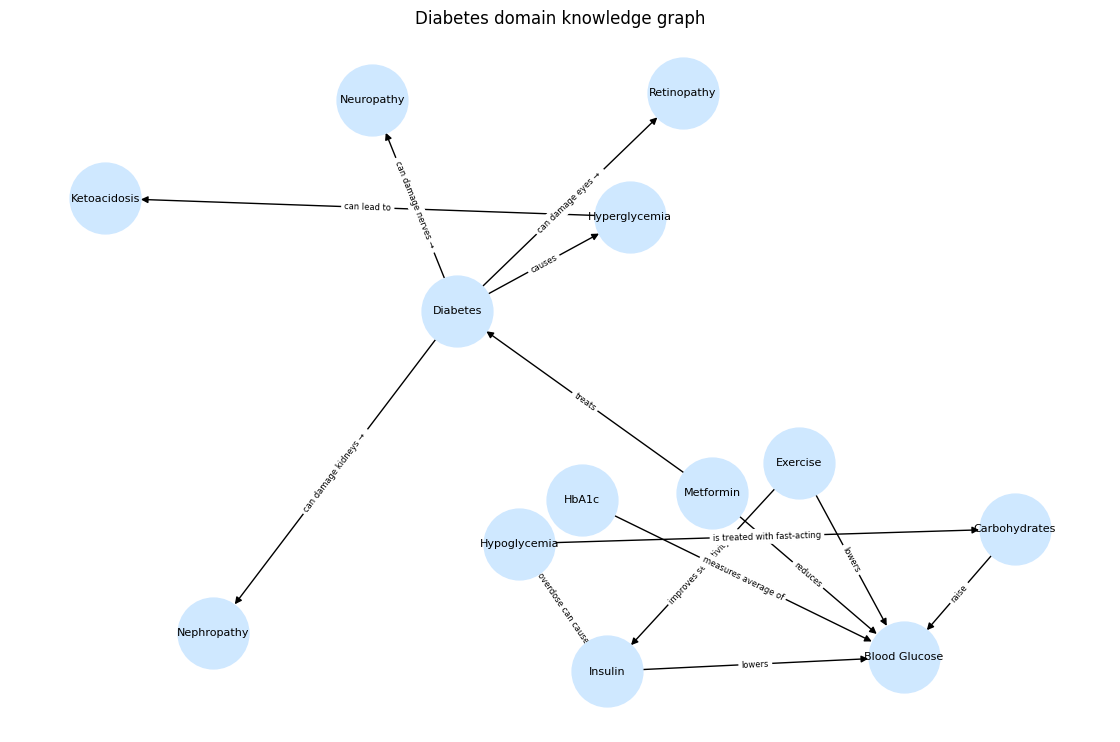

In [4]:
concept_keywords = {
 "Diabetes": ["diabet"], "Insulin": ["insulin"], "Blood Glucose": ["glucose", "blood sugar", "sugar"],
 "HbA1c": ["hba1c", "a1c"], "Hypoglycemia": ["hypoglyc", "low sugar", "low blood sugar"],
 "Hyperglycemia": ["hyperglyc", "high sugar", "high blood sugar"], "Metformin": ["metformin"],
 "Carbohydrates": ["carb", "rice", "bread", "sweet"], "Neuropathy": ["neuropath", "nerve"],
 "Retinopathy": ["retinopath", "eye"], "Nephropathy": ["nephropath", "kidney"],
 "Exercise": ["exercise", "walk", "yoga"], "Ketoacidosis": ["ketoacidosis", "dka", "fruity breath"],
}
relations = [
 ("Diabetes", "causes", "Hyperglycemia"), ("Insulin", "lowers", "Blood Glucose"),
 ("Metformin", "reduces", "Blood Glucose"), ("Metformin", "treats", "Diabetes"),
 ("Carbohydrates", "raise", "Blood Glucose"), ("Exercise", "lowers", "Blood Glucose"),
 ("HbA1c", "measures average of", "Blood Glucose"), ("Insulin", "overdose can cause", "Hypoglycemia"),
 ("Hypoglycemia", "is treated with fast-acting", "Carbohydrates"), ("Hyperglycemia", "can lead to", "Ketoacidosis"),
 ("Diabetes", "can damage nerves → ", "Neuropathy"), ("Diabetes", "can damage eyes → ", "Retinopathy"),
 ("Diabetes", "can damage kidneys → ", "Nephropathy"), ("Exercise", "improves sensitivity to", "Insulin"),
]
print(len(concept_keywords), "concepts,", len(relations), "relationships")
import networkx as nx
G = nx.DiGraph(); [G.add_edge(a, b, label=r) for a, r, b in relations]
plt.figure(figsize=(11, 7)); pos = nx.spring_layout(G, seed=4, k=1.1)
nx.draw(G, pos, with_labels=True, node_color="#cfe8ff", node_size=2600, font_size=8, arrows=True)
nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, "label"), font_size=6)
plt.title("Diabetes domain knowledge graph"); plt.show()

## 4. NLP preprocessing – lowercase, tokenize, stop-word removal, lemmatization

In [5]:
stop_words = set(stopwords.words("english")) - {"no", "not"}
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = text.lower()                                   # lowercase
    tokens = word_tokenize(text)                          # tokenization
    tokens = [t for t in tokens if t.isalnum()]
    tokens = [t for t in tokens if t not in stop_words]   # stop-word removal
    return " ".join(lemmatizer.lemmatize(lemmatizer.lemmatize(t), pos="v") for t in tokens)  # lemmatization

df["clean"] = df["query"].apply(preprocess)
df[["query", "clean"]].head(8)

,query,clean
0,what are the symptoms of diabetes,symptom diabetes
1,"I feel very thirsty and urinate a lot, is that...",feel thirsty urinate lot diabetes
2,early warning signs of type 2 diabetes,early warn sign type 2 diabetes
3,why do I feel tired and have blurry vision,feel tire blurry vision
4,what does high blood sugar feel like,high blood sugar feel like
5,do frequent infections indicate diabetes,frequent infection indicate diabetes
6,signs of type 1 diabetes in children,sign type 1 diabetes child
7,my wounds heal slowly what could be the reason,wind heal slowly could reason


## 5 & 6. TF-IDF, train Naive Bayes / Logistic Regression / SVM, evaluate

,Model,Accuracy,Precision,Recall,F1
0,Naive Bayes,0.719,0.697,0.719,0.696
1,Logistic Regression,0.688,0.661,0.688,0.667
2,SVM (linear),0.656,0.639,0.656,0.641


Best model: Naive Bayes
               precision    recall  f1-score   support

complications       0.80      1.00      0.89         4
         diet       0.80      1.00      0.89         4
    emergency       0.67      0.80      0.73         5
    lifestyle       0.75      0.60      0.67         5
   medication       0.83      1.00      0.91         5
   monitoring       0.33      0.25      0.29         4
     symptoms       0.67      0.40      0.50         5

     accuracy                           0.72        32
    macro avg       0.69      0.72      0.70        32
 weighted avg       0.70      0.72      0.70        32



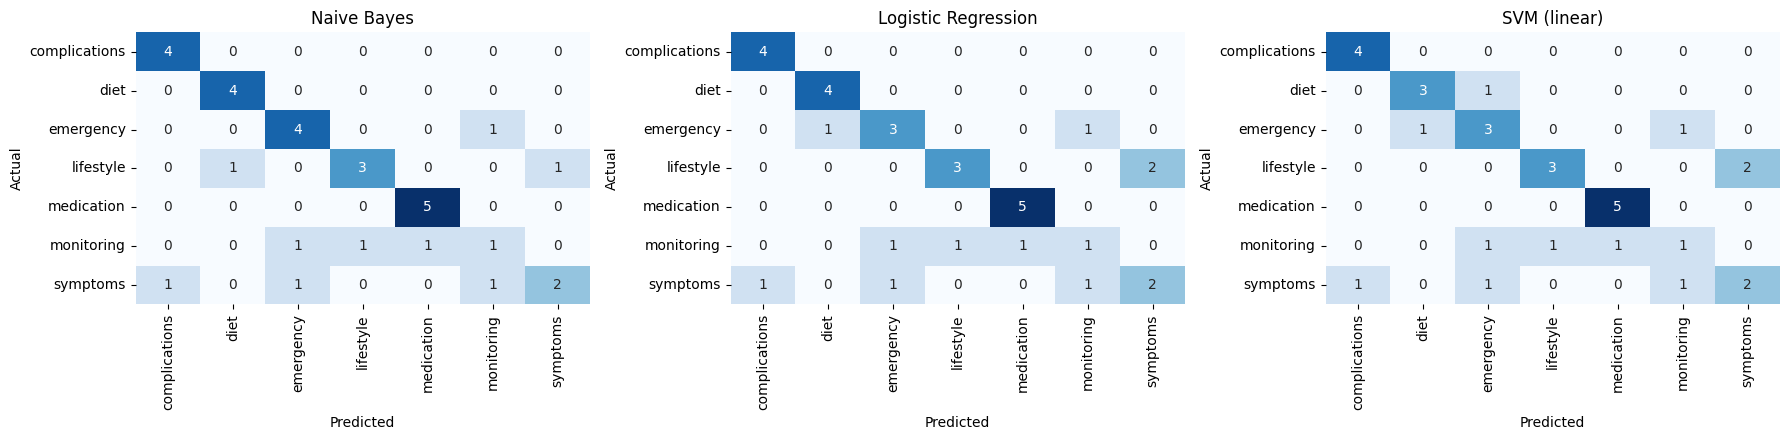


5-fold cross-validated accuracy (more reliable on a small corpus):
  Naive Bayes            0.721 ± 0.096
  Logistic Regression    0.729 ± 0.113
  SVM (linear)           0.729 ± 0.113


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["intent"], test_size=0.25, stratify=df["intent"], random_state=42)

tfidf = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
Xtr, Xte = tfidf.fit_transform(X_train), tfidf.transform(X_test)

models = {
 "Naive Bayes": MultinomialNB(alpha=0.3),
 "Logistic Regression": LogisticRegression(C=20, max_iter=2000),
 "SVM (linear)": SVC(kernel="linear", C=2, probability=True, random_state=42),
}
rows, preds = [], {}
for name, m in models.items():
    m.fit(Xtr, y_train); p = m.predict(Xte); preds[name] = p
    rows.append([name, accuracy_score(y_test, p),
                 precision_score(y_test, p, average="weighted", zero_division=0),
                 recall_score(y_test, p, average="weighted", zero_division=0),
                 f1_score(y_test, p, average="weighted", zero_division=0)])
results = pd.DataFrame(rows, columns=["Model", "Accuracy", "Precision", "Recall", "F1"]).round(3)
display(results)
best_name = results.sort_values(["F1", "Accuracy"], ascending=False).iloc[0]["Model"]
print("Best model:", best_name)
print(classification_report(y_test, preds[best_name], zero_division=0))

labels = sorted(df.intent.unique())
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, (name, p) in zip(ax, preds.items()):
    sns.heatmap(confusion_matrix(y_test, p, labels=labels), annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels, ax=a, cbar=False)
    a.set_title(name); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
plt.tight_layout(); plt.show()

from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
skf = StratifiedKFold(5, shuffle=True, random_state=0)
print("\n5-fold cross-validated accuracy (more reliable on a small corpus):")
for name, m in models.items():
    pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True), type(m)(**m.get_params()))
    sc = cross_val_score(pipe, df["clean"], df["intent"], cv=skf)
    print(f"  {name:22s} {sc.mean():.3f} ± {sc.std():.3f}")

# Deployment model: refit best model on ALL data
tfidf_full = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
X_all = tfidf_full.fit_transform(df["clean"])
final_model = type(models[best_name])(**models[best_name].get_params()).fit(X_all, df["intent"])

## 7. Domain knowledge base (one entry per intent)

In [7]:
knowledge_base = {
 "symptoms": "Common diabetes symptoms: excessive thirst, frequent urination, extreme hunger, unexplained weight loss, fatigue, blurred vision, slow-healing wounds and frequent infections. Type 1 often appears suddenly in children/young adults; Type 2 develops gradually. Diagnosis needs blood tests (fasting glucose ≥126 mg/dL, HbA1c ≥6.5%, or OGTT) ordered by a doctor.",
 "diet": "Diabetes-friendly eating: choose whole grains, millets, pulses, vegetables, nuts and lean protein; control carbohydrate portions; prefer low-glycemic foods; limit sugary drinks, sweets, refined flour and fried foods; eat at regular times. Whole fruit in moderate portions is generally fine. A dietitian can personalise a plan.",
 "medication": "Common treatments: Metformin (reduces liver glucose output and improves insulin sensitivity), sulfonylureas, DPP-4 inhibitors, SGLT2 inhibitors, and insulin (basal long-acting, bolus rapid-acting). Never start, stop or change a dose without your doctor. Taking medicines on time with meals as advised prevents highs and lows.",
 "monitoring": "Typical targets (individualise with your doctor): fasting 80–130 mg/dL, 1–2 hours after meals <180 mg/dL, HbA1c usually <7%. HbA1c reflects the average of the last ~3 months. Test using a glucometer (fasting, pre-meal, bedtime) or a CGM sensor; frequency depends on your treatment.",
 "complications": "Long-term high sugar can damage small and large vessels: retinopathy (eyes), nephropathy (kidneys), neuropathy (nerves, foot ulcers), and increased risk of heart disease and stroke. Prevention: good glucose, BP and cholesterol control, yearly eye/kidney/foot checks, no smoking.",
 "lifestyle": "Aim for ≥150 minutes/week of moderate activity (e.g. brisk walking) plus strength training, which improves insulin sensitivity. Weight loss, 7–8 hours of sleep, stress management (yoga, meditation) and quitting smoking all improve control. Check sugar before/after exercise and carry a fast-acting carbohydrate.",
 "emergency": "🚨 POSSIBLE DIABETIC EMERGENCY. If the person is conscious and sugar is low (<70 mg/dL): give 15 g fast sugar (glucose tablets, juice) and recheck in 15 minutes. If unconscious, seizing, vomiting with fruity breath, or confused: call emergency services (India: 112 / 108) IMMEDIATELY. Do not give food or drink to an unconscious person.",
}
disclaimer = "\n\nℹ️ General information only – please consult your doctor/diabetologist for personal advice."

## 8. Rule engine + 9. Integrated assistant

In [8]:
EMERGENCY_PATTERN = re.compile(r"unconscious|seizure|not breathing|can.?t breathe|fruity breath|passed out|faint|"
                               r"very low sugar|severe hypo|ketoacidosis|dka|sugar.{0,12}(above|over|>)\s*(3|4|5)\d\d|"
                               r"chest pain|emergency|confus|faint|shaky|sweating|coma|not waking|unresponsive", re.I)
DOSAGE_PATTERN = re.compile(r"how (many|much) (units|mg|tablets|insulin)|what dose|exact dose|dosage|prescribe|"
                            r"change my dose|increase my dose", re.I)
GREETING_PATTERN = re.compile(r"^\s*(hi|hello|hey|namaste|good (morning|evening|afternoon))\b", re.I)
OTHER_DISEASE = re.compile(r"cancer|covid|dengue|malaria|asthma|migraine|fever|pregnan|heart attack|blood pressure|"
                           r"weather|cricket|movie|stock|recipe for cake", re.I)
CONF_THRESHOLD, SIM_THRESHOLD = 0.35, 0.12
train_matrix = tfidf_full.transform(df["clean"])

def find_concepts(text):
    t = text.lower()
    return [c for c, kws in concept_keywords.items() if any(k in t for k in kws)]

def reasoning(concepts):
    out = []
    for a, r, b in relations:
        if a in concepts or b in concepts:
            out.append(f"{a} —{r}→ {b}")
    return out[:4]

def assistant(query):
    q_clean = preprocess(query)
    vec = tfidf_full.transform([q_clean])
    sim = float(cosine_similarity(vec, train_matrix).max()) if q_clean else 0.0
    proba = final_model.predict_proba(vec)[0]
    intent, conf = final_model.classes_[proba.argmax()], float(proba.max())
    concepts = find_concepts(query)
    res = {"query": query, "intent": intent, "confidence": round(conf, 2), "rule": None, "concepts": concepts}

    if EMERGENCY_PATTERN.search(query):                                   # Rule 1 – emergency escalation
        res.update(rule="R1 Emergency escalation", intent="emergency", response=knowledge_base["emergency"])
    elif GREETING_PATTERN.search(query) and len(query.split()) <= 4:      # Rule 2 – greeting
        res.update(rule="R2 Greeting", intent="greeting",
                   response="Hello! I'm your Diabetes Care Assistant. Ask me about symptoms, diet, medicines, monitoring, complications or lifestyle.")
    elif OTHER_DISEASE.search(query) or (sim < SIM_THRESHOLD and not concepts):   # Rule 3 – unsupported query
        res.update(rule="R3 Unsupported query", intent="unsupported",
                   response="Sorry, I can only help with diabetes-related questions. For other health topics please consult a doctor.")
    elif DOSAGE_PATTERN.search(query):                                    # Rule 4 – dosage safety
        res.update(rule="R4 Dosage safety", response="I can't recommend or change medicine/insulin doses – these depend on your readings, weight and history. Please ask your doctor or diabetes educator.\n\nGeneral info: " + knowledge_base["medication"])
    elif conf < CONF_THRESHOLD:                                           # Rule 5 – low-confidence handling
        res.update(rule="R5 Low confidence", intent="unclear",
                   response="I'm not sure I understood. Could you rephrase? For example: 'What foods should I avoid?' or 'How often should I check my sugar?'")
    else:
        res.update(response=knowledge_base[intent] + disclaimer)
        if intent in ("complications", "symptoms") and re.search(r"\bchild|\bchildren|\bkids?\b", query, re.I):
            res["rule"] = "R6 Pediatric note"; res["response"] += "\n👶 For children, consult a paediatric endocrinologist promptly."   # Rule 6
    if res["intent"] in intent_to_taxonomy:
        res["taxonomy"] = " > ".join(intent_to_taxonomy[res["intent"]])
    res["reasoning"] = reasoning(concepts)                                # Reasoning over knowledge graph
    return res

def show(res):
    print("="*80); print("🧑 Query     :", res["query"])
    print("🎯 Intent    :", res["intent"], f"(confidence {res['confidence']})", "| Rule:", res["rule"])
    if res.get("taxonomy"): print("🗂  Taxonomy  :", res["taxonomy"])
    if res["reasoning"]: print("🧠 Reasoning :", " ; ".join(res["reasoning"]))
    print("🤖 Assistant :", res["response"])

## Testing the assistant

In [9]:
tests = [
 ("1. Query for each intent", ["What are the symptoms of diabetes?", "Which foods should a diabetic avoid?", "How does metformin work?",
   "How often should I check my blood sugar?", "Can diabetes damage my kidneys?", "Does walking help control sugar?",
   "My father is diabetic and is unconscious, help!"]),
 ("2. Differently worded query", ["I am always thirsty and have to pass urine very often, could it be diabetes?"]),
 ("3. Unsupported query", ["How do I treat dengue fever?", "Who won the cricket match yesterday?"]),
 ("4. Low-confidence query", ["Is it good for me?"]),
 ("5. Emergency query", ["Sugar is 40 and I am sweating, shaky and might faint"]),
 ("Extra – dosage rule", ["How many units of insulin should I take?"]),
]
for title, qs in tests:
    print("\n\n######", title)
    for q in qs: show(assistant(q))



###### 1. Query for each intent
🧑 Query     : What are the symptoms of diabetes?
🎯 Intent    : symptoms (confidence 0.55) | Rule: None
🗂  Taxonomy  : Understanding Diabetes > Symptoms & Diagnosis
🧠 Reasoning : Diabetes —causes→ Hyperglycemia ; Metformin —treats→ Diabetes ; Diabetes —can damage nerves → → Neuropathy ; Diabetes —can damage eyes → → Retinopathy
🤖 Assistant : Common diabetes symptoms: excessive thirst, frequent urination, extreme hunger, unexplained weight loss, fatigue, blurred vision, slow-healing wounds and frequent infections. Type 1 often appears suddenly in children/young adults; Type 2 develops gradually. Diagnosis needs blood tests (fasting glucose ≥126 mg/dL, HbA1c ≥6.5%, or OGTT) ordered by a doctor.

ℹ️ General information only – please consult your doctor/diabetologist for personal advice.
🧑 Query     : Which foods should a diabetic avoid?
🎯 Intent    : diet (confidence 0.52) | Rule: None
🗂  Taxonomy  : Lifestyle Management > Nutrition
🧠 Reasoning : Diabetes 

## 10. Interactive interface (Colab) – enter one or many queries (one per line)

In [10]:
import ipywidgets as widgets
from IPython.display import display, clear_output
box = widgets.Textarea(placeholder="Type one or more questions, one per line…", layout=widgets.Layout(width="95%", height="110px"))
btn = widgets.Button(description="Ask Assistant", button_style="success", icon="stethoscope")
out = widgets.Output()
def on_click(_):
    with out:
        clear_output()
        for line in [l.strip() for l in box.value.splitlines() if l.strip()]:
            show(assistant(line))
btn.on_click(on_click)
display(widgets.HTML("<h3>🩺 Diabetes Care Assistant</h3>"), box, btn, out)

HTML(value='<h3>🩺 Diabetes Care Assistant</h3>')

Textarea(value='', layout=Layout(height='110px', width='95%'), placeholder='Type one or more questions, one pe…

Button(button_style='success', description='Ask Assistant', icon='stethoscope', style=ButtonStyle())

Output()